## EX8 Supervised Learning: Linear Regression


### Set up

In [7]:
# Python ≥3.5 is required
import sys
assert sys.version_info >= (3, 5)

# Scikit-Learn ≥0.20 is required
import sklearn
assert sklearn.__version__ >= "0.20"

# Common imports
import numpy as np
import pandas as pd
import os
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

# To plot pretty figures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)


# to make this notebook's output stable across runs
np.random.seed(42)

# Where to save the figures
PROJECT_ROOT_DIR = "."
CHAPTER_ID = "decision_trees"
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images", CHAPTER_ID)

os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

## Part 0

Explore linear regression and regularized linear regression models.
    - Linear regression
    - Rige regression
    - Lasso regression

- Read and run each cell of the given examples: (1) synthetic dataset (2) crime dataset

- Understand the results. In particular, see how feature normalization affects on ridges regression and how the model performance changes when varying alpha parameter values are used in both ridge regression and Lasso regression.

## Linear models for regression

- scikit learn

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

### Model evaluation metrics for regression

Model evaluation metrics for regression models
Evaluation metrics for classification problems, such as accuracy, are not useful for regression problems. Instead, we need evaluation metrics designed for comparing continuous values.

See more details: https://scikit-learn.org/stable/modules/model_evaluation.html


**Mean Absolute Error** (MAE) is the mean of the absolute value of the errors:

$$\frac 1n\sum_{i=1}^n|y_i-\hat{y}_i|$$


**Mean Squared Error** (MSE) is the mean of the squared errors:

$$\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2$$


**Root Mean Squared Error** (RMSE) is the square root of the mean of the squared errors:

$$\sqrt{\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2}$$


Comparing these metrics:

- **MAE** is the easiest to understand, because it's the average error.
- **MSE** is more popular than MAE, because MSE "punishes" larger errors.
- **RMSE** is even more popular than MSE, because RMSE is interpretable in the "y" units.


#### The R2 ("r-squared") Regression Score

- Measures how well a prediction model for regression fits the given data.

- The score is between 0 and 1:

     - A value of 0 corresponds to a constant model that predicts the mean value of all training target values.

     - A value of 1 corresponds to perfect prediction

- Also known as "coefficient of determination"

### Preparing X and Y using pandas
- We already did this process above
- scikit-learn expects X (feature matrix) and Y (response vector) to be NumPy arrays.
- However, pandas is built on top of NumPy.
- Thus, X can be a pandas DataFrame and y can be a pandas Series!

### Dataset 1: Synthetic random data points

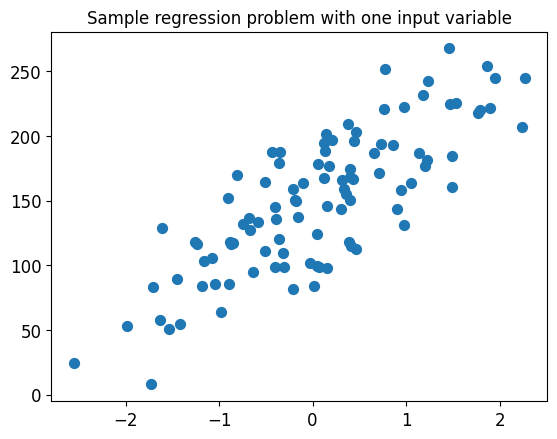

In [8]:
from sklearn.datasets import make_classification, make_blobs
from matplotlib.colors import ListedColormap

# synthetic dataset for simple regression
from sklearn.datasets import make_regression

plt.figure()
plt.title('Sample regression problem with one input variable')
X_R1, y_R1 = make_regression(n_samples = 100, n_features=1,
                             n_informative=1, bias = 150.0,
                             noise = 30, random_state=0)

plt.scatter(X_R1, y_R1, marker= 'o', s=50)
plt.show()

In [3]:
from sklearn.linear_model import LinearRegression

X_train, X_test, y_train, y_test = train_test_split(X_R1, y_R1, random_state=0)

linreg = LinearRegression().fit(X_train, y_train)

#### Linear regression model coefficient and intercept values \& performance metrics

In [4]:
from sklearn import metrics

print('linear model intercept (b): {:.3f}'.format(linreg.intercept_))
print('linear model coeff (w): {}'.format(linreg.coef_))

# train data R2
print('R-squared score (training): {:.3f}'.format(linreg.score(X_train, y_train)))
# test data R2
print('R-squared score (test): {:.3f}'.format(linreg.score(X_test, y_test)))

# make predictions on the testing set and print RMSE
y_pred = linreg.predict(X_test)
print('RMSE: {:.3f}'.format(np.sqrt(metrics.mean_squared_error(y_test, y_pred))))

linear model intercept (b): 148.446
linear model coeff (w): [45.70870465]
R-squared score (training): 0.679
R-squared score (test): 0.492
RMSE: 33.203


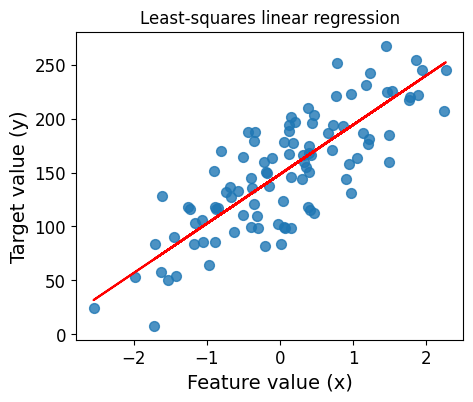

In [5]:
plt.figure(figsize=(5,4))
plt.scatter(X_R1, y_R1, marker= 'o', s=50, alpha=0.8)
plt.plot(X_R1, linreg.coef_ * X_R1 + linreg.intercept_, 'r-')
plt.title('Least-squares linear regression')
plt.xlabel('Feature value (x)')
plt.ylabel('Target value (y)')
plt.show()

### Dataset 2: crime dataset

In [9]:
def load_crime_dataset():
    # Communities and Crime dataset for regression
    # https://archive.ics.uci.edu/ml/datasets/Communities+and+Crime+Unnormalized

    # na_values='?'
    crime = pd.read_csv('/CommViolPredUnnormalizedData.csv')
    # remove features with poor coverage or lower relevance, and keep ViolentCrimesPerPop target column
    columns_to_keep = [5, 6] + list(range(11,26)) + list(range(32, 103)) + [145]

    crime = crime.iloc[:, columns_to_keep]
    crime = crime.dropna()

    X_crime = crime.iloc[:, 0:88]
    y_crime = crime['ViolentCrimesPerPop']

    return (X_crime, y_crime)

# Communities and Crime dataset
(X_crime, y_crime) = load_crime_dataset()

print(X_crime.head())
print(y_crime.head())

   population  householdsize  agePct12t21  agePct12t29  agePct16t24  \
0       11980           3.10        12.47        21.44        10.93   
1       23123           2.82        11.01        21.30        10.48   
2       29344           2.43        11.36        25.88        11.01   
3       16656           2.40        12.55        25.20        12.19   
4       11245           2.76        24.46        40.53        28.69   

   agePct65up  numbUrban  pctUrban  medIncome  pctWWage  ...  \
0       11.33      11980     100.0      75122     89.24  ...   
1       17.18      23123     100.0      47917     78.99  ...   
2       10.28      29344     100.0      35669     82.00  ...   
3       17.57          0       0.0      20580     68.15  ...   
4       12.65          0       0.0      17390     69.33  ...   

   MedRentPctHousInc  MedOwnCostPctInc  MedOwnCostPctIncNoMtg  NumInShelters  \
0               23.8              21.1                   14.0             11   
1               27.6        

#### Linear regression on crime dataset (without regularization)

In [12]:
# Reload the crime dataset specifying '?' as NaN so they can be dropped properly
def load_crime_dataset_fixed():
    crime = pd.read_csv('/CommViolPredUnnormalizedData.csv', na_values='?')
    columns_to_keep = [5, 6] + list(range(11,26)) + list(range(32, 103)) + [145]
    crime = crime.iloc[:, columns_to_keep]
    crime = crime.dropna()
    X_crime = crime.iloc[:, 0:88]
    y_crime = crime['ViolentCrimesPerPop'].astype(float)
    return (X_crime, y_crime)

# Load cleaned data
(X_crime, y_crime) = load_crime_dataset_fixed()

X_train, X_test, y_train, y_test = train_test_split(X_crime, y_crime, random_state=0)
linreg = LinearRegression().fit(X_train, y_train)

print('Crime dataset')
print('R-squared score (training): {:.3f}'
     .format(linreg.score(X_train, y_train)))
print('R-squared score (test): {:.3f}'
     .format(linreg.score(X_test, y_test)))

# make predictions on the testing set
y_pred = linreg.predict(X_test)
print('RMSE: {:.3f}'.format(np.sqrt(metrics.mean_squared_error(y_test, y_pred))))

print('linear model intercept: {}'.format(linreg.intercept_))
print('linear model coeff:\n{}'.format(linreg.coef_))

print('Number of non-zero features: {}'.format(np.sum(linreg.coef_ != 0)))

Crime dataset
R-squared score (training): 0.673
R-squared score (test): 0.496
RMSE: 454.949
linear model intercept: -1728.130672600671
linear model coeff:
[ 1.61892346e-03 -9.43009110e+01  1.36067510e+01 -3.13380670e+01
 -8.15482725e-02 -1.69455128e+01 -2.42730375e-03  1.53013232e+00
 -1.39193248e-02 -7.72112833e+00  2.28112354e+01 -5.65708295e+00
  9.34751364e+00  2.06969566e-01 -7.43413626e+00  9.65856476e-03
  4.38030290e-03  4.79754625e-03 -4.46469212e+00 -1.60907140e+01
  8.82778012e+00 -5.06734503e-01 -1.42198055e+00  8.17551991e+00
 -3.87048268e+00 -3.54209213e+00  4.48758304e+00  9.30645715e+00
  1.73644996e+02  1.18220766e+01  1.51120836e+02 -3.29613007e+02
 -1.35343395e+02  6.95380108e-01 -2.38369008e+01  2.77038981e+00
  3.82248925e-01  4.38813358e+00 -1.06410851e+01 -4.92294176e-03
  4.14031827e+01 -1.16206866e-03  1.18568968e+00  1.75418465e+00
 -3.68283678e+00  1.59679443e+00 -8.42180230e+00 -3.79703897e+01
  4.74076990e+01 -2.50768374e+01 -2.88246410e-01 -3.65633234e+01


### Ridge regression (regularized regression)

In [13]:
from sklearn.linear_model import Ridge
X_train, X_test, y_train, y_test = train_test_split(X_crime, y_crime, random_state=0)

linridge = Ridge(alpha=20.0).fit(X_train, y_train)

print('Crime dataset')

print('R-squared score (training): {:.3f}'
     .format(linridge.score(X_train, y_train)))
print('R-squared score (test): {:.3f}'
     .format(linridge.score(X_test, y_test)))

# make predictions on the testing set
y_pred = linreg.predict(X_test)
print('RMSE: {:.3f}'.format(np.sqrt(metrics.mean_squared_error(y_test, y_pred))))

print('ridge regression linear model intercept: {}'.format(linridge.intercept_))
print('ridge regression linear model coeff:\n{}'.format(linridge.coef_))

print('Number of non-zero features: {}'.format(np.sum(linridge.coef_ != 0)))

Crime dataset
R-squared score (training): 0.671
R-squared score (test): 0.494
RMSE: 454.949
ridge regression linear model intercept: -3352.4230358461004
ridge regression linear model coeff:
[ 1.95091438e-03  2.19322667e+01  9.56286607e+00 -3.59178973e+01
  6.36465325e+00 -1.96885471e+01 -2.80715856e-03  1.66254486e+00
 -6.61426604e-03 -6.95450680e+00  1.71944731e+01 -5.62819154e+00
  8.83525114e+00  6.79085746e-01 -7.33614221e+00  6.70389803e-03
  9.78505502e-04  5.01202169e-03 -4.89870524e+00 -1.79270062e+01
  9.17572382e+00 -1.24454193e+00  1.21845360e+00  1.03233089e+01
 -3.78037278e+00 -3.73428973e+00  4.74595305e+00  8.42696855e+00
  3.09250005e+01  1.18644167e+01 -2.05183675e+00 -3.82210450e+01
  1.85081589e+01  1.52510829e+00 -2.20086608e+01  2.46283912e+00
  3.29328703e-01  4.02228467e+00 -1.12903533e+01 -4.69567413e-03
  4.27046505e+01 -1.22507167e-03  1.40795790e+00  9.35041855e-01
 -3.00464253e+00  1.12390514e+00 -1.82487653e+01 -1.54653407e+01
  2.41917002e+01 -1.32497562e+

### Ridge regression with feature normalization

In [14]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

from sklearn.linear_model import Ridge
X_train, X_test, y_train, y_test = train_test_split(X_crime, y_crime,
                                                   random_state = 0)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

linridge = Ridge(alpha=20.0).fit(X_train_scaled, y_train)

print('Crime dataset')
print('R-squared score (training): {:.3f}'
     .format(linridge.score(X_train_scaled, y_train)))
print('R-squared score (test): {:.3f}'
     .format(linridge.score(X_test_scaled, y_test)))

# make predictions on the testing set
y_pred = linreg.predict(X_test)
print('RMSE: {:.3f}'.format(np.sqrt(metrics.mean_squared_error(y_test, y_pred))))

print('ridge regression linear model intercept: {}'.format(linridge.intercept_))
print('ridge regression linear model coeff:\n{}'.format(linridge.coef_))

print('Number of non-zero features: {}'.format(np.sum(linridge.coef_ != 0)))

Crime dataset
R-squared score (training): 0.615
R-squared score (test): 0.599
RMSE: 454.949
ridge regression linear model intercept: 933.3906385044157
ridge regression linear model coeff:
[  88.68827454   16.48947987  -50.30285445  -82.90507574  -65.89507244
   -2.27674244   87.74108514  150.94862182   18.8802613   -31.05554992
  -43.13536109 -189.44266328   -4.52658099  107.97866804  -76.53358414
    2.86032762   34.95230077   90.13523036   52.46428263  -62.10898424
  115.01780357    2.66942023    6.94331369   -5.66646499 -101.55269144
  -36.9087526    -8.7053343    29.11999068  171.25963057   99.36919476
   75.06611841  123.63522539   95.24316483 -330.61044265 -442.30179004
 -284.49744001 -258.37150609   17.66431072 -101.70717151  110.64762887
  523.13611718   24.8208959     4.86533322  -30.46775619   -3.51753937
   50.57947231   10.84840601   18.27680946   44.11189865   58.33588176
   67.08698975  -57.93524659  116.1446052    53.81163718   49.01607711
   -7.62262031   55.14288543  -

### Ridge regression with regularization parameter: alpha

In [15]:
print('Ridge regression: effect of alpha regularization parameter\n')
for this_alpha in [0, 1, 10, 20, 50, 100, 1000]:
    linridge = Ridge(alpha = this_alpha).fit(X_train_scaled, y_train)
    r2_train = linridge.score(X_train_scaled, y_train)
    r2_test = linridge.score(X_test_scaled, y_test)
    num_coeff_bigger = np.sum(abs(linridge.coef_) > 1.0)
    print('Alpha = {:.2f}\nnum abs(coeff) > 1.0: {}, \
r-squared training: {:.2f}, r-squared test: {:.2f}\n'
         .format(this_alpha, num_coeff_bigger, r2_train, r2_test))

Ridge regression: effect of alpha regularization parameter

Alpha = 0.00
num abs(coeff) > 1.0: 88, r-squared training: 0.67, r-squared test: 0.50

Alpha = 1.00
num abs(coeff) > 1.0: 87, r-squared training: 0.66, r-squared test: 0.56

Alpha = 10.00
num abs(coeff) > 1.0: 87, r-squared training: 0.63, r-squared test: 0.59

Alpha = 20.00
num abs(coeff) > 1.0: 88, r-squared training: 0.61, r-squared test: 0.60

Alpha = 50.00
num abs(coeff) > 1.0: 86, r-squared training: 0.58, r-squared test: 0.58

Alpha = 100.00
num abs(coeff) > 1.0: 87, r-squared training: 0.55, r-squared test: 0.55

Alpha = 1000.00
num abs(coeff) > 1.0: 84, r-squared training: 0.31, r-squared test: 0.30



### Lasso regression

In [16]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

X_train, X_test, y_train, y_test = train_test_split(X_crime, y_crime,
                                                   random_state = 0)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

linlasso = Lasso(alpha=2.0, max_iter = 10000).fit(X_train_scaled, y_train)

print('Crime dataset')

print('R-squared score (training): {:.3f}'
     .format(linlasso.score(X_train_scaled, y_train)))
print('R-squared score (test): {:.3f}\n'
     .format(linlasso.score(X_test_scaled, y_test)))

# make predictions on the testing set
y_pred = linreg.predict(X_test)
print('RMSE: {:.3f}'.format(np.sqrt(metrics.mean_squared_error(y_test, y_pred))))

print('lasso regression linear model intercept: {}'.format(linlasso.intercept_))
print('lasso regression linear model coeff:\n{}'.format(linlasso.coef_))

print('Non-zero features: {}'.format(np.sum(linlasso.coef_ != 0)))

print('Features with non-zero weight (sorted by absolute magnitude):')
for e in sorted (list(zip(list(X_crime), linlasso.coef_)),
                key = lambda e: -abs(e[1])):
    if e[1] != 0:
        print('\t{}, {:.3f}'.format(e[0], e[1]))

Crime dataset
R-squared score (training): 0.631
R-squared score (test): 0.624

RMSE: 454.949
lasso regression linear model intercept: 1186.612061998579
lasso regression linear model coeff:
[    0.             0.            -0.          -168.18346054
    -0.            -0.             0.           119.6938194
     0.            -0.             0.          -169.67564456
    -0.             0.            -0.             0.
     0.             0.            -0.            -0.
     0.            -0.             0.             0.
   -57.52991966    -0.            -0.             0.
   259.32889226    -0.             0.             0.
     0.            -0.         -1188.7396867     -0.
    -0.            -0.          -231.42347299     0.
  1488.36512229     0.            -0.            -0.
    -0.             0.             0.             0.
     0.             0.            -0.             0.
    20.14419415     0.             0.             0.
     0.             0.           339.04468804 

### Lasso regression with regularization parameter: alpha

In [17]:
print('Lasso regression: effect of alpha regularization\n\
parameter on number of features kept in final model\n')

for alpha in [0.5, 1, 2, 3, 5, 10, 20, 50]:
    linlasso = Lasso(alpha, max_iter = 10000).fit(X_train_scaled, y_train)
    r2_train = linlasso.score(X_train_scaled, y_train)
    r2_test = linlasso.score(X_test_scaled, y_test)

    print('Alpha = {:.2f}\nFeatures kept: {}, r-squared training: {:.2f}, \
r-squared test: {:.2f}\n'
         .format(alpha, np.sum(linlasso.coef_ != 0), r2_train, r2_test))

Lasso regression: effect of alpha regularization
parameter on number of features kept in final model

Alpha = 0.50
Features kept: 35, r-squared training: 0.65, r-squared test: 0.58

Alpha = 1.00
Features kept: 25, r-squared training: 0.64, r-squared test: 0.60

Alpha = 2.00
Features kept: 20, r-squared training: 0.63, r-squared test: 0.62

Alpha = 3.00
Features kept: 17, r-squared training: 0.62, r-squared test: 0.63

Alpha = 5.00
Features kept: 12, r-squared training: 0.60, r-squared test: 0.61

Alpha = 10.00
Features kept: 6, r-squared training: 0.57, r-squared test: 0.58

Alpha = 20.00
Features kept: 2, r-squared training: 0.51, r-squared test: 0.50

Alpha = 50.00
Features kept: 1, r-squared training: 0.31, r-squared test: 0.30



## Part1:

The best practice is to define a classification program for the dataset(s) of your term project.

In case a classification problem is not possibly defined for your datasets, you can use the sample dataset below (cancer dataset).

Apply the following regression model on datasets of your project.

(1) Linear regression without regularization

(2) Ridge regression

(3) Ridge regression with feature normalization

(4) Ridge regression with regularization parameter: alpha

(5) Lasso regression

(6) Lasso regression with regularization parameter: alpha

#### Sample dataset: Breast cancer dataset

In [18]:
from sklearn.datasets import load_breast_cancer

# Breast cancer dataset for classification
cancer = load_breast_cancer()
(X_cancer, y_cancer) = load_breast_cancer(return_X_y = True)

print(cancer.feature_names)
print(y_cancer)

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 1 0 1 1 1 1 1 0 0 1 0 0 1 1 1 1 0 1 0 0 1 1 1 1 0 1 0 0
 1 0 1 0 0 1 1 1 0 0 1 0 0 0 1 1 1 0 1 1 0 0 1 1 1 0 0 1 1 1 1 0 1 1 0 1 1
 1 1 1 1 1 1 0 0 0 1 0 0 1 1 1 0 0 1 0 1 0 0 1 0 0 1 1 0 1 1 0 1 1 1 1 0 1
 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 0 1 1 0 0 1 1 0 0 1 1 1 1 0 1 1 0 0 0 1 0
 1 0 1 1 1 0 1 1 0 0 1 0 0 0 0 1 0 0 0 1 0 1 0 1 1 0 1 0 0 0 0 1 1 0 0

(1) Linear regression without regularization

In [19]:
X_tr, X_te, y_tr, y_te = train_test_split(X_cancer, y_cancer, random_state=0)
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import MinMaxScaler

def report(name, model, Xtr, Xte, ytr=None, yte=None):
    """Print R2, RMSE (computed from THIS model), classification accuracy at 0.5, and #non-zero coefficients."""
    ytr = y_tr if ytr is None else ytr
    yte = y_te if yte is None else yte
    pred = model.predict(Xte)
    rmse = np.sqrt(metrics.mean_squared_error(yte, pred))
    acc = np.mean((pred > 0.5).astype(int) == yte)
    print('{}\n  R2 train: {:.3f} | R2 test: {:.3f} | test RMSE: {:.3f} | test acc@0.5: {:.3f} | non-zero coef: {}'
          .format(name, model.score(Xtr, ytr), model.score(Xte, yte), rmse, acc, np.sum(model.coef_ != 0)))

linreg = LinearRegression().fit(X_tr, y_tr)
report('Linear regression (no regularization)', linreg, X_tr, X_te)
print('intercept:', linreg.intercept_)
print('coefficients:\n', linreg.coef_)

Linear regression (no regularization)
  R2 train: 0.782 | R2 test: 0.729 | test RMSE: 0.251 | test acc@0.5: 0.972 | non-zero coef: 30
intercept: 3.264323682949688
coefficients:
 [ 1.95664033e-01 -1.24998359e-02 -1.83925145e-02 -3.08554299e-04
 -6.58769659e-01  4.67316114e+00 -1.41047944e+00 -1.79519061e+00
 -1.02466251e+00 -8.16682870e-01 -6.95506836e-01 -2.65194673e-02
  6.52894932e-02  3.22253562e-04 -1.16323309e+01 -4.43943865e-02
  3.04134165e+00 -8.31729413e+00 -2.44644000e+00  1.96844051e+01
 -1.78964757e-01 -2.00410588e-04 -4.02896117e-03  1.17548563e-03
 -4.04988322e-01 -1.15267671e-01 -4.11583121e-01 -9.11239745e-01
 -1.12925131e-01 -5.02459596e+00]


(2) Ridge regression

In [20]:
ridge = Ridge(alpha=20.0).fit(X_tr, y_tr)
report('Ridge (alpha=20, raw features)', ridge, X_tr, X_te)
print('coefficients:\n', ridge.coef_)

Ridge (alpha=20, raw features)
  R2 train: 0.718 | R2 test: 0.701 | test RMSE: 0.264 | test acc@0.5: 0.958 | non-zero coef: 30
coefficients:
 [ 8.95459514e-02  4.96576604e-03 -6.53071472e-03 -9.38715208e-06
 -1.70744323e-02 -2.48627421e-02 -4.93503540e-02 -2.77020642e-02
 -3.06915402e-02 -4.70309146e-03 -4.64609813e-02 -1.10244435e-02
 -1.66584359e-02 -3.44749865e-04 -2.54152959e-03  2.62285611e-04
 -1.16547194e-03 -2.54907417e-03 -5.31339660e-03 -7.79367812e-05
 -1.60523115e-01 -1.55701325e-02 -6.49252297e-03  1.01356127e-03
 -3.15652552e-02 -8.47221763e-02 -1.40803334e-01 -5.21846681e-02
 -6.76483639e-02 -1.53442711e-02]


(3) Ridge regression with feature normalization

In [21]:
scaler = MinMaxScaler()
X_tr_s = scaler.fit_transform(X_tr)   # fit on training data only
X_te_s = scaler.transform(X_te)

ridge_s = Ridge(alpha=20.0).fit(X_tr_s, y_tr)
report('Ridge (alpha=20, MinMax-scaled features)', ridge_s, X_tr_s, X_te_s)
print('coefficients:\n', ridge_s.coef_)

Ridge (alpha=20, MinMax-scaled features)
  R2 train: 0.698 | R2 test: 0.696 | test RMSE: 0.266 | test acc@0.5: 0.951 | non-zero coef: 30
coefficients:
 [-0.15953124 -0.14083798 -0.15623107 -0.11422388 -0.0739519  -0.07506947
 -0.11895532 -0.191061   -0.07479776  0.06879125 -0.07719428 -0.00264562
 -0.05536349 -0.03226534  0.02846709  0.04759806  0.03104476 -0.02518334
 -0.00139326  0.04768871 -0.20126066 -0.16533176 -0.18362235 -0.1237563
 -0.13628769 -0.11408258 -0.13774801 -0.27762586 -0.13141221 -0.05403194]


(4) Ridge regression with regularization parameter: alpha

Ridge regression (scaled features): effect of alpha

alpha=       0: R2 train 0.782, R2 test 0.729, #|coef|>1: 8
alpha=    0.01: R2 train 0.781, R2 test 0.732, #|coef|>1: 5
alpha=     0.1: R2 train 0.775, R2 test 0.736, #|coef|>1: 3
alpha=       1: R2 train 0.750, R2 test 0.726, #|coef|>1: 0
alpha=      10: R2 train 0.717, R2 test 0.709, #|coef|>1: 0
alpha=      20: R2 train 0.698, R2 test 0.696, #|coef|>1: 0
alpha=      50: R2 train 0.646, R2 test 0.653, #|coef|>1: 0
alpha=     100: R2 train 0.567, R2 test 0.578, #|coef|>1: 0
alpha=    1000: R2 train 0.157, R2 test 0.162, #|coef|>1: 0


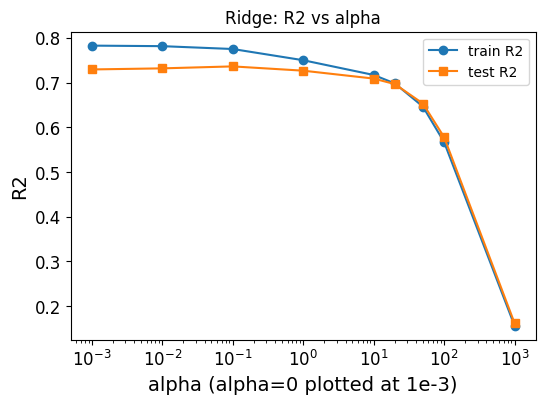

In [22]:
print('Ridge regression (scaled features): effect of alpha\n')
ridge_alphas = [0, 0.01, 0.1, 1, 10, 20, 50, 100, 1000]
ridge_res = []
for a in ridge_alphas:
    r = Ridge(alpha=a).fit(X_tr_s, y_tr)
    ridge_res.append((a, r.score(X_tr_s, y_tr), r.score(X_te_s, y_te), np.sum(abs(r.coef_) > 1.0)))
    print('alpha={:>8}: R2 train {:.3f}, R2 test {:.3f}, #|coef|>1: {}'.format(*ridge_res[-1]))

plt.figure(figsize=(6,4))
plt.semilogx([max(r[0],1e-3) for r in ridge_res], [r[1] for r in ridge_res], 'o-', label='train R2')
plt.semilogx([max(r[0],1e-3) for r in ridge_res], [r[2] for r in ridge_res], 's-', label='test R2')
plt.xlabel('alpha (alpha=0 plotted at 1e-3)'); plt.ylabel('R2'); plt.title('Ridge: R2 vs alpha'); plt.legend(); plt.show()

(5) Lasso regression

In [23]:
lasso = Lasso(alpha=0.01, max_iter=100000).fit(X_tr_s, y_tr)
report('Lasso (alpha=0.01, scaled features)', lasso, X_tr_s, X_te_s)
print('Features kept (sorted by |coef|):')
for name, c in sorted(zip(cancer.feature_names, lasso.coef_), key=lambda e: -abs(e[1])):
    if c != 0:
        print('\t{}: {:.3f}'.format(name, c))

Lasso (alpha=0.01, scaled features)
  R2 train: 0.690 | R2 test: 0.688 | test RMSE: 0.270 | test acc@0.5: 0.951 | non-zero coef: 5
Features kept (sorted by |coef|):
	worst concave points: -1.056
	worst radius: -0.675
	mean texture: -0.097
	worst texture: -0.083
	mean concave points: -0.010


(6) Lasso regression with regularization parameter: alpha

Lasso regression (scaled features): effect of alpha

alpha= 0.0001: features kept 26, R2 train 0.780, R2 test 0.736
alpha=  0.001: features kept 15, R2 train 0.737, R2 test 0.721
alpha=  0.005: features kept  7, R2 train 0.711, R2 test 0.712
alpha=   0.01: features kept  5, R2 train 0.690, R2 test 0.688
alpha=   0.02: features kept  2, R2 train 0.634, R2 test 0.627
alpha=   0.05: features kept  1, R2 train 0.423, R2 test 0.421
alpha=    0.1: features kept  0, R2 train 0.000, R2 test -0.000
alpha=    0.5: features kept  0, R2 train 0.000, R2 test -0.000
alpha=      1: features kept  0, R2 train 0.000, R2 test -0.000


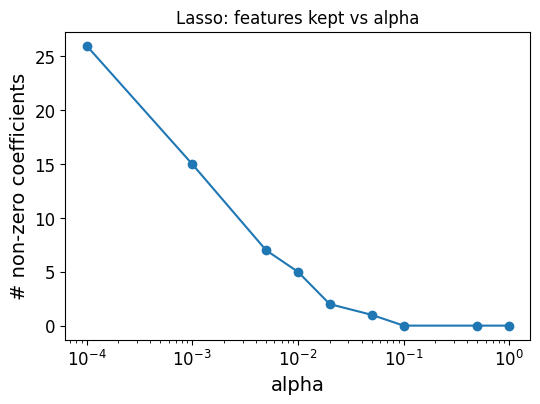

In [24]:
print('Lasso regression (scaled features): effect of alpha\n')
lasso_alphas = [0.0001, 0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.5, 1]
lasso_res = []
for a in lasso_alphas:
    l = Lasso(alpha=a, max_iter=100000).fit(X_tr_s, y_tr)
    lasso_res.append((a, np.sum(l.coef_ != 0), l.score(X_tr_s, y_tr), l.score(X_te_s, y_te)))
    print('alpha={:>7}: features kept {:>2}, R2 train {:.3f}, R2 test {:.3f}'.format(*lasso_res[-1]))

plt.figure(figsize=(6,4))
plt.semilogx(lasso_alphas, [r[1] for r in lasso_res], 'o-')
plt.xlabel('alpha'); plt.ylabel('# non-zero coefficients'); plt.title('Lasso: features kept vs alpha'); plt.show()

## Part2

Write a summary in Canvas

### Summary of findings (breast cancer dataset, 569 samples, 30 features, target 0/1)

The task is classification, so regression is used here only to illustrate the models: predictions are continuous scores, and I report R2 and RMSE plus accuracy after thresholding at 0.5. All metrics use the same 75/25 split (`random_state=0`). Note that the example cells above compute RMSE from `linreg` for every model; in my cells RMSE comes from the model being evaluated.

| Model | R2 train | R2 test | Test RMSE | Non-zero coef |
|---|---|---|---|---|
| (1) Linear regression | 0.782 | 0.729 | 0.251 | 30 |
| (2) Ridge, alpha=20, raw features | 0.718 | 0.701 | 0.264 | 30 |
| (3) Ridge, alpha=20, MinMax-scaled | 0.698 | 0.696 | 0.266 | 30 |
| (5) Lasso, alpha=0.01, MinMax-scaled | 0.690 | 0.688 | 0.270 | 5 |

- **Unregularized regression** has the best R2 here but the largest train-test gap, and huge coefficients of mixed sign (up to about 20 in magnitude). Many features are strongly correlated (radius, perimeter, area), so these coefficients are unstable.
- **Ridge on raw features** shrinks coefficients, but unevenly, because features have very different scales. Penalizing without scaling is not a fair penalty. **Scaling** makes the penalty apply evenly and the coefficients comparable (all within about 0.3 in magnitude).
- **Ridge vs alpha** (scaled): test R2 peaks around alpha=0.1 (0.736, slightly above the unregularized 0.729), then drops steadily; at alpha=1000 the model underfits (R2 about 0.16). This is the usual bias-variance trade-off, with a modest gain from light regularization.
- **Lasso** zeroes out coefficients. At alpha=0.01 only 5 of 30 features remain (led by worst concave points and worst radius) with test R2 0.688, only about 0.04 below the full model. As alpha grows the number of features falls: 26, 15, 7, 5, 2, 1, then 0 at alpha >= 0.1, where the model predicts the mean (R2 = 0). Lasso gives a smaller, more interpretable model at a small cost in accuracy.
- **Overall**: regularization gives little accuracy benefit on this data (the dataset is large relative to its features), but it stabilizes coefficients (Ridge) and selects features (Lasso). All models reach 95-97% accuracy at the 0.5 threshold, though a classifier such as logistic regression is the natural choice for this target.
